# Adel, 6: with other models

**What you will learn:** what coupling Adel with another model means, on a ready-made example: the canopy lit by a
simple light model.

**You need:** tutorial 1. **Run time:** a few seconds.

Adel builds the plants' 3D shape. Its main use is to give it to other models: a **light model** computes the light each
leaf receives from the leaves' triangles, a growth model uses that light to make the organs grow, and so on. In
metafspm, models are combined in a **plant model** (see the last section of tutorial 1).

## 1. A stand lit by a light model

`example/light_coupling.py` (in this repository) defines `LitShoot`: Adel's plant model `ScenarioShoot` with a toy light
model added after the shoot. The light model applies **Beer's law** in vertical columns of 5 cm: a leaf receives less
light the more leaf area lies above it. It is a toy to show the coupling, not a validated light model.

`simulate` grows a stand of 12 plants of that plant model:

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "../..")                         # example/light_coupling.py
from light_coupling import LitShoot
from openalea.adel.simulation import simulate

stand = simulate(days=60, plants=12, model=LitShoot)
ds = stand.data_structure
light = np.asarray(ds.get("light_fraction"))       # per element: the fraction of the light above the canopy
print(f"{len(ds.entity_ids('Plant'))} plants, {ds.n_nodes()} elements")

12 plants, 2706 elements


The light model wrote one new variable per element, `light_fraction`: the fraction of the light above the canopy that
reaches it. The stand coloured by it:

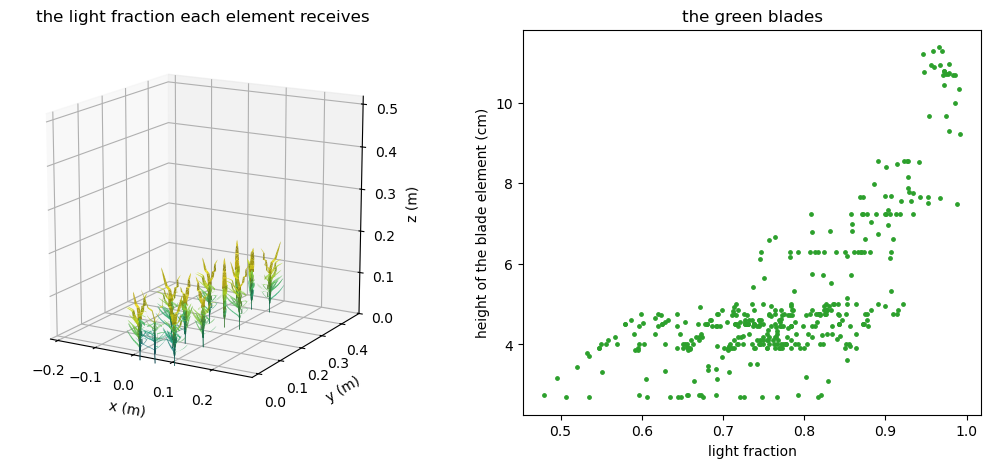

In [2]:
fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
stand.draw(ax, color_by="light_fraction")
ax.set_title("the light fraction each element receives")
ax = fig.add_subplot(1, 2, 2)
green_blade = (np.asarray(ds.labels()) == "LeafElement") & (np.asarray(ds.get("green_area")) > 0)
middle = (np.asarray(ds.get("z1")) + np.asarray(ds.get("z2"))) / 2
ax.scatter(light[green_blade], middle[green_blade] * 100, s=6, c="tab:green")
ax.set_xlabel("light fraction"); ax.set_ylabel("height of the blade element (cm)")
ax.set_title("the green blades");

The top blades receive most of the light, the lower ones less: they are shaded by the leaves above.

## 2. A real light model: Caribu

Caribu (the package `openalea.caribu`) is a validated light model for plant canopies, written for metafspm too. It
reads Adel's triangles the same way, and also computes the light scattered between leaves. Its own user tutorials
(in the Caribu repository, `example/tutorials/user/`) light Adel's canopies step by step.

## 3. Going further

To couple Adel with your own models, you write a plant model: which components it contains, in which order they run,
and which variable each one gives to another. The developer tutorials show how:
`../developer/01_shoot_architecture_in_metafspm.ipynb` (its coupling contract section) and
`../developer/02_extend_the_component.ipynb`.

## Try it yourself

1. Grow the stand for 80 days. Does the canopy's lower part get less light?
2. Grow 24 plants instead of 12 (`plants=24`): does the mean light fraction change?